In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score, KFold
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.svm import SVR
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, median_absolute_error

In [ ]:
df=pd.read_csv("data/House_Rent_Dataset.csv")
df

,Posted On,BHK,Rent,Size,Floor,Area Type,Area Locality,City,Furnishing Status,Tenant Preferred,Bathroom,Point of Contact
0,2022-05-18,2,10000,1100,Ground out of 2,Super Area,Bandel,Kolkata,Unfurnished,Bachelors/Family,2,Contact Owner
1,2022-05-13,2,20000,800,1 out of 3,Super Area,"Phool Bagan, Kankurgachi",Kolkata,Semi-Furnished,Bachelors/Family,1,Contact Owner
2,2022-05-16,2,17000,1000,1 out of 3,Super Area,Salt Lake City Sector 2,Kolkata,Semi-Furnished,Bachelors/Family,1,Contact Owner
3,2022-07-04,2,10000,800,1 out of 2,Super Area,Dumdum Park,Kolkata,Unfurnished,Bachelors/Family,1,Contact Owner
4,2022-05-09,2,7500,850,1 out of 2,Carpet Area,South Dum Dum,Kolkata,Unfurnished,Bachelors,1,Contact Owner
...,...,...,...,...,...,...,...,...,...,...,...,...
4741,2022-05-18,2,15000,1000,3 out of 5,Carpet Area,Bandam Kommu,Hyderabad,Semi-Furnished,Bachelors/Family,2,Contact Owner
4742,2022-05-15,3,29000,2000,1 out of 4,Super Area,"Manikonda, Hyderabad",Hyderabad,Semi-Furnished,Bachelors/Family,3,Contact Owner
4743,2022-07-10,3,35000,1750,3 out of 5,Carpet Area,"Himayath Nagar, NH 7",Hyderabad,Semi-Furnished,Bachelors/Family,3,Contact Agent
4744,2022-07-06,3,45000,1500,23 out of 34,Carpet Area,Gachibowli,Hyderabad,Semi-Furnished,Family,2,Contact Agent


In [ ]:
df.dropna()

,Posted On,BHK,Rent,Size,Floor,Area Type,Area Locality,City,Furnishing Status,Tenant Preferred,Bathroom,Point of Contact
0,2022-05-18,2,10000,1100,Ground out of 2,Super Area,Bandel,Kolkata,Unfurnished,Bachelors/Family,2,Contact Owner
1,2022-05-13,2,20000,800,1 out of 3,Super Area,"Phool Bagan, Kankurgachi",Kolkata,Semi-Furnished,Bachelors/Family,1,Contact Owner
2,2022-05-16,2,17000,1000,1 out of 3,Super Area,Salt Lake City Sector 2,Kolkata,Semi-Furnished,Bachelors/Family,1,Contact Owner
3,2022-07-04,2,10000,800,1 out of 2,Super Area,Dumdum Park,Kolkata,Unfurnished,Bachelors/Family,1,Contact Owner
4,2022-05-09,2,7500,850,1 out of 2,Carpet Area,South Dum Dum,Kolkata,Unfurnished,Bachelors,1,Contact Owner
...,...,...,...,...,...,...,...,...,...,...,...,...
4741,2022-05-18,2,15000,1000,3 out of 5,Carpet Area,Bandam Kommu,Hyderabad,Semi-Furnished,Bachelors/Family,2,Contact Owner
4742,2022-05-15,3,29000,2000,1 out of 4,Super Area,"Manikonda, Hyderabad",Hyderabad,Semi-Furnished,Bachelors/Family,3,Contact Owner
4743,2022-07-10,3,35000,1750,3 out of 5,Carpet Area,"Himayath Nagar, NH 7",Hyderabad,Semi-Furnished,Bachelors/Family,3,Contact Agent
4744,2022-07-06,3,45000,1500,23 out of 34,Carpet Area,Gachibowli,Hyderabad,Semi-Furnished,Family,2,Contact Agent


In [ ]:
df['Rent'].skew()

np.float64(21.409942283288803)

In [ ]:
print(df["Floor"].str.split().str[-1].value_counts())

Floor
4         938
3         915
2         868
5         422
1         335
         ... 
54          1
85          1
71          1
81          1
Ground      1
Name: count, Length: 67, dtype: int64


In [ ]:
df["for_family"]   = df["Tenant Preferred"].str.contains("Family", case=False).astype(int)
df["for_bachelor"] = df["Tenant Preferred"].str.contains("Bachelor", case=False).astype(int)
df["my_floor"] = df["Floor"].str.split().str[0]
df["total_floor"] = df["Floor"].str.split().str[-1]
df["my_floor"]=df["my_floor"].map(lambda x : 0 if x=="Ground" else x)
df["my_floor"]=df["my_floor"].map(lambda x : -1 if x=="Upper" else x)
df["my_floor"]=df["my_floor"].map(lambda x : -2 if x=="Lower" else x)

In [ ]:
df.columns


Index(['Posted On', 'BHK', 'Rent', 'Size', 'Floor', 'Area Type',
       'Area Locality', 'City', 'Furnishing Status', 'Tenant Preferred',
       'Bathroom', 'Point of Contact', 'for_family', 'for_bachelor',
       'my_floor', 'total_floor'],
      dtype='object')

In [ ]:
df.describe()


,BHK,Rent,Size,Bathroom,for_family,for_bachelor
count,4746.000000,4.746000e+03,4746.000000,4746.000000,4746.000000,4746.000000
mean,2.083860,3.499345e+04,967.490729,1.965866,0.825116,0.900548
std,0.832256,7.810641e+04,634.202328,0.884532,0.379908,0.299300
min,1.000000,1.200000e+03,10.000000,1.000000,0.000000,0.000000
25%,2.000000,1.000000e+04,550.000000,1.000000,1.000000,1.000000
50%,2.000000,1.600000e+04,850.000000,2.000000,1.000000,1.000000
75%,3.000000,3.300000e+04,1200.000000,2.000000,1.000000,1.000000
max,6.000000,3.500000e+06,8000.000000,10.000000,1.000000,1.000000


In [ ]:
df["total_floor"].value_counts()

,count
total_floor,
4,938
3,915
2,868
5,422
1,335
...,...
54,1
85,1
71,1


In [ ]:
df["total_floor"].value_counts(dropna=True)

,count
total_floor,
4,938
3,915
2,868
5,422
1,335
...,...
54,1
85,1
71,1


In [ ]:
df.describe()

,BHK,Rent,Size,Bathroom,for_family,for_bachelor
count,4746.000000,4.746000e+03,4746.000000,4746.000000,4746.000000,4746.000000
mean,2.083860,3.499345e+04,967.490729,1.965866,0.825116,0.900548
std,0.832256,7.810641e+04,634.202328,0.884532,0.379908,0.299300
min,1.000000,1.200000e+03,10.000000,1.000000,0.000000,0.000000
25%,2.000000,1.000000e+04,550.000000,1.000000,1.000000,1.000000
50%,2.000000,1.600000e+04,850.000000,2.000000,1.000000,1.000000
75%,3.000000,3.300000e+04,1200.000000,2.000000,1.000000,1.000000
max,6.000000,3.500000e+06,8000.000000,10.000000,1.000000,1.000000


In [ ]:
df = df[df["Bathroom"] < 7]

num = pd.to_numeric(df["total_floor"], errors="coerce")   # pehle num banao
bad = num.isna() & df["total_floor"].notna()              # text wali rows
print(df[bad])                                          # kitni rows hain

df = df[~bad]                                             # unko hatao
df["total_floor"] = pd.to_numeric(df["total_floor"])      # ab safe hai number banana

       Posted On  BHK   Rent  Size   Floor    Area Type  \
2883  2022-05-23    1  18000   450  Ground  Carpet Area   

                                  Area Locality   City Furnishing Status  \
2883  DDA Flat AD Block, Shalimar Bagh AD Block  Delhi         Furnished   

      Tenant Preferred  Bathroom Point of Contact  for_family  for_bachelor  \
2883  Bachelors/Family         1    Contact Owner           1             1   

     my_floor total_floor  
2883        0      Ground  


In [ ]:
df["my_floor"] = df["my_floor"].replace({"Ground": 0, "Upper": -1, "Lower": -2})
df["my_floor"] = pd.to_numeric(df["my_floor"])

In [ ]:
q1 = df["Rent"].quantile(0.30)
q2 = df["Rent"].quantile(0.70)
iqr = q2-q1
low = q1 - 1.5*iqr
high = q2 +1.5*iqr

df = df[(df["Rent"] >= max(0,low)) & (df["Rent"] <= high)]
df.describe()

q1 = df["Size"].quantile(0.25)
q2 = df["Size"].quantile(0.75)
iqr = q2-q1
low = q1 - 1.5*iqr
high = q2 +1.5*iqr

df = df[(df["Size"] >= max(0,low)) & (df["Size"] <= high)]
df.describe()

,BHK,Rent,Size,Bathroom,for_family,for_bachelor,my_floor,total_floor
count,3968.000000,3968.000000,3968.000000,3968.000000,3968.000000,3968.000000,3968.000000,3968.000000
mean,1.912802,17080.776966,830.633065,1.750000,0.834173,0.912802,2.310736,4.916079
std,0.706095,10693.027681,421.089957,0.656549,0.371972,0.282160,3.172221,5.288478
min,1.000000,1500.000000,10.000000,1.000000,0.000000,0.000000,-2.000000,1.000000
25%,1.000000,9000.000000,500.000000,1.000000,1.000000,1.000000,1.000000,2.000000
50%,2.000000,14000.000000,800.000000,2.000000,1.000000,1.000000,1.500000,3.000000
75%,2.000000,22000.000000,1100.000000,2.000000,1.000000,1.000000,3.000000,5.000000
max,6.000000,51000.000000,2000.000000,6.000000,1.000000,1.000000,34.000000,48.000000


<Axes: xlabel='Rent', ylabel='Count'>

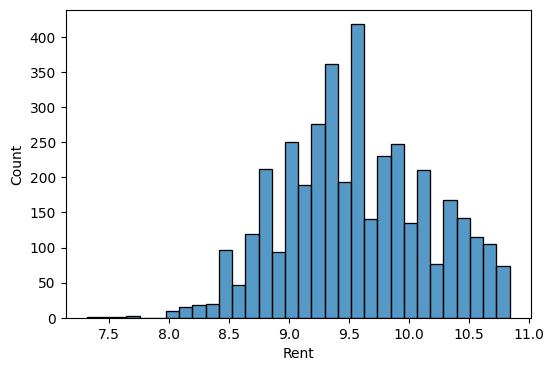

In [ ]:
plt.figure(figsize=(6,4))
sns.histplot(np.log1p(df["Rent"]))

In [ ]:
df=df[np.log1p(df["Rent"])>=8]

<Axes: xlabel='Size', ylabel='Count'>

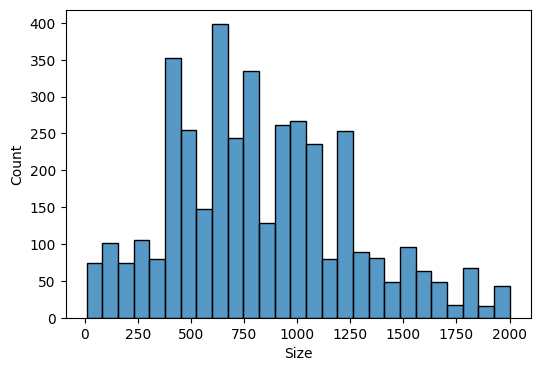

In [ ]:
plt.figure(figsize=(6,4))
sns.histplot(df["Size"])

<Axes: xlabel='Bathroom', ylabel='Count'>

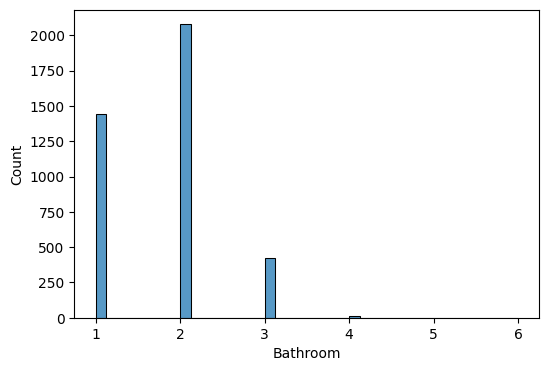

In [ ]:
plt.figure(figsize=(6,4))
sns.histplot(df["Bathroom"])

In [ ]:
df["Bathroom"] = df["Bathroom"].clip(upper=4)

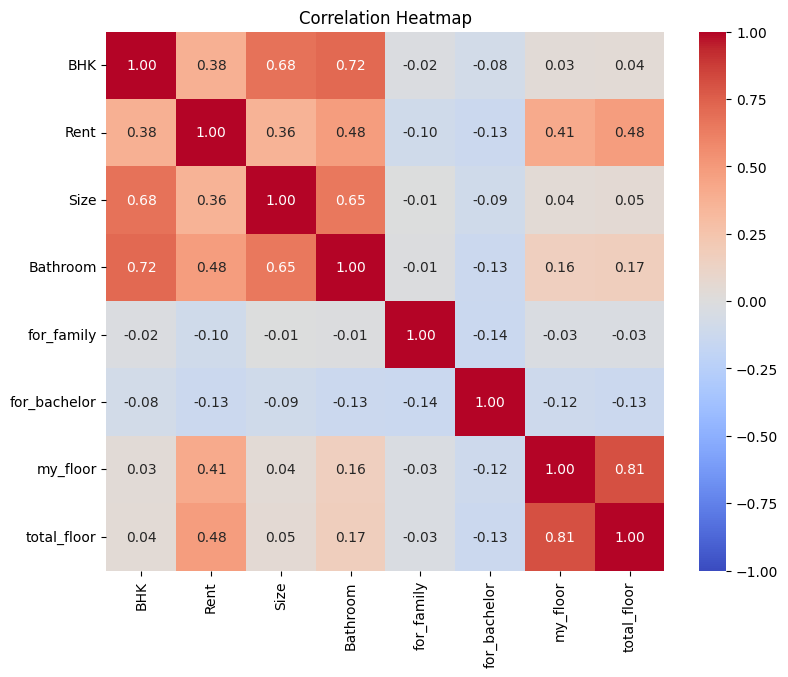

In [ ]:
plt.figure(figsize=(9, 7))
corr = df.corr(numeric_only=True)

sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlation Heatmap")
plt.show()

In [ ]:
from sklearn.preprocessing import TargetEncoder
from sklearn.impute import SimpleImputer

df = df[df["Size"] >= 100]

X = df.drop(columns=["Posted On", "Rent"])
y = np.log1p(df["Rent"])

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42)

cat_cols = ["Area Type", "City", "Furnishing Status", "Point of Contact"]
num_cols = ["BHK", "Size", "Bathroom", "for_family", "for_bachelor", "my_floor", "total_floor"]

preprocess = ColumnTransformer([
    ("cat", OneHotEncoder(handle_unknown="infrequent_if_exist", drop="first", min_frequency=10), cat_cols),
    ("loc", TargetEncoder(smooth="auto"), ["Area Locality"]),
    ("num", Pipeline([("imp", SimpleImputer(strategy="median")),
                      ("sc", StandardScaler())]), num_cols),
])

models = {
    "LinearRegression": LinearRegression(),
    "Ridge": Ridge(alpha=1.0),
    "Lasso": Lasso(alpha=0.001),
    "RandomForest": RandomForestRegressor(n_estimators=200, random_state=42, n_jobs=-1),
    "GradientBoosting": GradientBoostingRegressor(random_state=42),
    "SVR": SVR(kernel="rbf", C=10, epsilon=0.1),
}

results = []
for name, model in models.items():
    pipe = Pipeline([("prep", preprocess), ("model", model)])
    pipe.fit(X_train, y_train)
    pred = pipe.predict(X_test)

    actual_price = np.expm1(y_test)
    pred_price = np.expm1(pred)

    results.append({
        "model": name,
        "R2 (log)": r2_score(y_test, pred),
        "MAE": mean_absolute_error(actual_price, pred_price),
        "MedAE": median_absolute_error(actual_price, pred_price),
    })

pd.DataFrame(results).sort_values("MAE")

,model,R2 (log),MAE,MedAE
4,GradientBoosting,0.720952,3887.416158,2522.800755
5,SVR,0.720894,3915.785107,2492.382619
2,Lasso,0.710390,4035.364502,2397.999125
0,LinearRegression,0.710819,4048.379751,2405.040538
1,Ridge,0.710825,4049.051148,2414.907520
3,RandomForest,0.693016,4082.706891,2722.526623
